# Forecasting Apple's Quarterly Net Income: 8 Models, Two Validation Schemes and a Check Against the Reported Result

**This project extends Mini Project 1,** which ran a simple OLS regression of Apple's annual revenue on `Year`.

That mini project fitted a single straight line through 24 annual points and judged it on in-sample R². In a real
forecasting job that approach has three problems:
1. **No seasonality.** Apple earns about a third of its annual profit in its holiday quarter (fiscal Q1, Oct–Dec).
2. **No out-of-sample test.** In-sample R² says nothing about how accurate the forecasts are.
3. **No check against reality.** The forecast was never compared with a number Apple actually reported.

This notebook uses the same toolkit (`pandas`, `statsmodels`, `matplotlib`) on **43 quarters of net income
(FY2016 Q1 – FY2026 Q3)** and adds the following:

| Step | What is done |
|---|---|
| Data cleaning | Parse a messy hand-built Excel file into a tidy quarterly table |
| Data checks | Duplicates, missing quarters, quarter-on-quarter moves > 50%, reconciliation to annual totals, cross-check with Apple's filings |
| Models | Naive, **seasonal naive (main baseline)**, 4-quarter moving average, trend + season regression (log and linear), Holt-Winters, SARIMA (order chosen by AIC on training data only), and the Mini Project 1 trend line for reference |
| Validation 1 | **Hold-out**: train to FY2024 Q3, forecast the last 8 quarters |
| Validation 2 | **Rolling-origin cross-validation**: 6 origins, each forecasting 4 quarters ahead |
| Metrics | MAE, RMSE, MAPE, and % improvement over seasonal naive |
| Reality check | Forecast **FY2026 Q4** from data to June 2026, then compare with the figure Apple reported on 30 Oct 2026 |
| Output | CSV tables, 5 charts, a 4-quarter forecast (FY2027) and a summary of figures for a CV |

All figures are in **US$ millions**. Apple's fiscal year ends in late September, so fiscal Q1 is Oct–Dec.

In [1]:
import re, itertools, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
warnings.filterwarnings("ignore")          # silences statsmodels convergence chatter during the model grid search
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

## 1. Load the raw data

The raw file was compiled by hand from Apple's earnings releases and is kept exactly as received. Within each year the
quarters are out of order, and the labels are inconsistent (`"First quarter"`, `"First Quarter"`, `"Fouth quarter"`).
Some numbers are stored as text with commas and tab characters (`"22,236 \t"`), years are separated by blank rows,
and for FY2023 the annual total and the year label sit on different rows. The column header says *Revenue*, but the
values are **net income**: they reconcile to Apple's reported annual net income (Section 3).

In [2]:
raw = pd.read_excel("data/AAPL_NetIncome_raw.xlsx", header=None)
raw.head(12)

,0,1,2,3,4,5
0,NaN,Instrument,Revenue from Business Activities - Total ($),Date,Year ended net income,Year
1,NaN,NaN,18361,First quarter,45687,2016
2,NaN,NaN,10516,Second quarter,NaN,NaN
3,NaN,NaN,7796,Third quarter,NaN,NaN
4,NaN,NaN,9014,Fourth quarter,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,11029,Second quarter,48351,2017
7,NaN,NaN,8717,Third quarter,NaN,NaN
8,NaN,NaN,17891,First quarter,NaN,NaN
9,NaN,NaN,10714,Fourth quarter,NaN,NaN


## 2. Clean and reshape into a tidy quarterly table

In [3]:
body = raw.iloc[1:, 2:6].copy()
body.columns = ["NI", "Label", "AnnualNI", "Year"]

def to_number(x):
    """'22,236 \t' -> 22236.0 ; NaN stays NaN"""
    if pd.isna(x):
        return np.nan
    return float(re.sub(r"[^\d.]", "", str(x)))

QUARTER = {"first": 1, "second": 2, "third": 3, "fourth": 4, "fouth": 4}   # 'fouth' = typo in source

blocks, current = [], []                                  # each fiscal year = block of rows between blank rows
for _, r in body.iterrows():
    if pd.isna(r.NI) and pd.isna(r.Label):
        if current: blocks.append(pd.DataFrame(current)); current = []
    else:
        current.append(r)
if current: blocks.append(pd.DataFrame(current))

rows, annual = [], {}
for b in blocks:
    fy = int(b.Year.dropna().iloc[0])                     # the year label can sit on any row of the block
    if b.AnnualNI.notna().any():
        annual[fy] = to_number(b.AnnualNI.dropna().iloc[0])
    for _, r in b.iterrows():
        rows.append({"FY": fy, "Q": QUARTER[str(r.Label).strip().split()[0].lower()], "NI_reported": to_number(r.NI)})

df = pd.DataFrame(rows).sort_values(["FY", "Q"]).reset_index(drop=True)
df["period"] = "FY" + df.FY.astype(str).str[2:] + " Q" + df.Q.astype(str)
df.pivot(index="FY", columns="Q", values="NI_reported")

Q,1,2,3,4
FY,,,,
2016,"18,361.00","10,516.00","7,796.00","9,014.00"
2017,"17,891.00","11,029.00","8,717.00","10,714.00"
2018,"20,065.00","13,822.00","11,519.00","14,125.00"
2019,"19,965.00","11,561.00","10,044.00","13,686.00"
2020,"22,236.00","11,249.00","11,253.00","12,673.00"
2021,"28,775.00","23,630.00","21,744.00","20,531.00"
2022,"34,630.00","25,010.00","19,442.00","20,721.00"
2023,"29,998.00","24,160.00","19,881.00","22,956.00"
2024,"33,916.00","23,636.00","21,448.00","14,736.00"


## 3. Data checks

In [4]:
# Check 1 - duplicate quarters
dups = df[df.duplicated(["FY", "Q"], keep=False)]
# Check 2 - missing quarters between the first and last observation
expected = [(fy, q) for fy in range(df.FY.min(), df.FY.max() + 1) for q in range(1, 5)]
expected = expected[: expected.index((df.FY.iloc[-1], df.Q.iloc[-1])) + 1]
missing = sorted(set(expected) - set(zip(df.FY, df.Q)))
# Check 3 - quarter-on-quarter moves larger than 50%
df["qoq_%"] = df.NI_reported.pct_change() * 100
big_moves = df.loc[df["qoq_%"].abs() > 50, ["period", "NI_reported", "qoq_%"]]
# Check 4 - the four quarters must add up to the reported annual figure
recon = pd.DataFrame({"sum_of_quarters": df.groupby("FY").NI_reported.sum(), "reported_annual": pd.Series(annual)})
recon["difference"] = recon.sum_of_quarters - recon.reported_annual

print(f"Duplicates: {len(dups)}   Missing quarters: {missing or 'none'}   Quarters observed: {len(df)}")
print(f"Annual reconciliation: {int((recon.difference == 0).sum())}/{int(recon.reported_annual.notna().sum())} complete years match exactly")
print(f"\nQuarter-on-quarter moves > 50% ({len(big_moves)} flagged):")
print(big_moves.assign(fiscal_quarter=df.loc[big_moves.index, "Q"]).to_string(index=False))

Duplicates: 0   Missing quarters: none   Quarters observed: 43
Annual reconciliation: 10/10 complete years match exactly

Quarter-on-quarter moves > 50% (7 flagged):
 period  NI_reported  qoq_%  fiscal_quarter
FY17 Q1    17,891.00  98.48               1
FY18 Q1    20,065.00  87.28               1
FY20 Q1    22,236.00  62.47               1
FY21 Q1    28,775.00 127.06               1
FY22 Q1    34,630.00  68.67               1
FY25 Q1    36,330.00 146.54               1
FY26 Q1    42,097.00  53.27               1


**Reading the checks**

* There are no duplicates or gaps, and every complete year reconciles exactly to the reported annual figure.
* **Every quarter flagged by the >50% rule is a fiscal Q1, the holiday quarter.** These are genuine seasonal jumps,
  not errors. For a seasonal business the rule produces false positives.
* **None of the four automated checks catches the real errors in this file.** A quarter-by-quarter comparison with Apple's
  earnings releases found two transposition errors in FY2021 that cancel out:

| Quarter | In file | Apple reported | Source |
|---|---|---|---|
| FY2021 Q1 (Dec 2020) | 28,775 | **28,755** | Apple Q1 FY21 press release, Business Wire, 27 Jan 2021 |
| FY2021 Q4 (Sep 2021) | 20,531 | **20,551** | Apple Q4 FY21 results ($20.55bn), 28 Oct 2021 |

28,775 + 20,531 = 28,755 + 20,551 = 49,306, so the annual sum still matched, and each error is only 0.1%, far too small
for a movement rule to flag. **Lesson:** automated checks catch structural problems, but small keying errors are only
found by reconciling against the source document.

In [5]:
df["NI"] = df.NI_reported
for (fy, q), v in {(2021, 1): 28755, (2021, 4): 20551}.items():
    df.loc[(df.FY == fy) & (df.Q == q), "NI"] = v
assert (df.groupby("FY").NI.sum().loc[list(annual)] == pd.Series(annual)).all()   # still reconciles after the fix
df[df.FY == 2021][["period", "NI_reported", "NI"]]

,period,NI_reported,NI
20,FY21 Q1,"28,775.00","28,755.00"
21,FY21 Q2,"23,630.00","23,630.00"
22,FY21 Q3,"21,744.00","21,744.00"
23,FY21 Q4,"20,531.00","20,551.00"


**One-off item.** FY2024 Q4 net income (14,736) includes a **one-time $10.2bn income-tax charge** from the EU State Aid
ruling. Following normal analyst practice, models are trained and scored on **underlying net income**, which adds the
10,200 back for that quarter.

In [6]:
df["NI_adj"] = df.NI
df.loc[(df.FY == 2024) & (df.Q == 4), "NI_adj"] += 10200
df.drop(columns="qoq_%").to_csv("data/AAPL_quarterly_net_income_clean.csv", index=False)
y_all, q_all, labels = df.NI_adj.values, df.Q.values, df.period.tolist()
df.tail(6)

,FY,Q,NI_reported,period,qoq_%,NI,NI_adj
37,2025,2,"24,780.00",FY25 Q2,-31.79,"24,780.00","24,780.00"
38,2025,3,"23,434.00",FY25 Q3,-5.43,"23,434.00","23,434.00"
39,2025,4,"27,466.00",FY25 Q4,17.21,"27,466.00","27,466.00"
40,2026,1,"42,097.00",FY26 Q1,53.27,"42,097.00","42,097.00"
41,2026,2,"29,578.00",FY26 Q2,-29.74,"29,578.00","29,578.00"
42,2026,3,"29,789.00",FY26 Q3,0.71,"29,789.00","29,789.00"


## 4. Explore: trend and seasonality

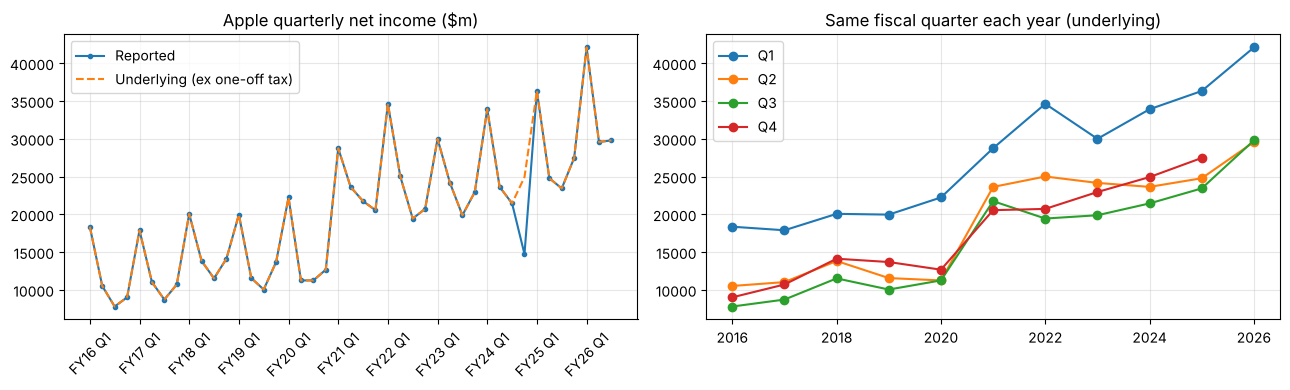

Share of annual net income by fiscal quarter, FY16-FY25 (%): {1: 33.9, 2: 23.2, 3: 20.1, 4: 22.9}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df.index, df.NI, marker="o", ms=3, label="Reported")
ax[0].plot(df.index, df.NI_adj, ls="--", label="Underlying (ex one-off tax)")
ax[0].set_xticks(df.index[::4]); ax[0].set_xticklabels(df.period[::4], rotation=45)
ax[0].set_title("Apple quarterly net income ($m)"); ax[0].legend()
for q, g in df.groupby("Q"):
    ax[1].plot(g.FY, g.NI_adj, marker="o", label=f"Q{q}")
ax[1].set_title("Same fiscal quarter each year (underlying)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/01_trend_seasonality.png", dpi=110); plt.show()

share = df[df.FY < 2026].groupby("Q").NI_adj.sum() / df[df.FY < 2026].NI_adj.sum() * 100
print("Share of annual net income by fiscal quarter, FY16-FY25 (%):", share.round(1).to_dict())

## 5. Models

Each model is a function that takes a training history and returns forecasts for the next `h` quarters. Any model
choice that has to be estimated (Holt-Winters settings, SARIMA orders) is made **inside the function, using only the
training data passed to it**. No information from the test period can leak into model selection.

| Model | Description |
|---|---|
| Naive | Repeat the last quarter |
| **Seasonal naive** | Repeat the same quarter of last year. **This is the main baseline**: a model has to beat it to be worth using |
| MA(4) | Average of the last 4 quarters |
| Mini Project 1 trend | `NI ~ t` (OLS, no seasonality), kept for reference |
| Regression, log | `log(NI) ~ t + C(Q)`: constant growth rate, multiplicative seasonality |
| Regression, linear | `NI ~ t + C(Q)`: linear trend, additive seasonality |
| Holt-Winters | Additive trend; additive or multiplicative season and damped or undamped trend, chosen by AIC |
| SARIMA | `log(NI)`, SARIMA(p,d,q)(P,1,Q)₄ with p, d, q, P, Q ∈ {0,1}, order chosen by AIC |

In [8]:
def future_quarters(q_train, h):
    return [(q_train[-1] + k - 1) % 4 + 1 for k in range(1, h + 1)]

def reg_forecast(formula, y, q, h, log=False, alpha=0.05):
    n = len(y)
    d = pd.DataFrame({"NI": y, "t": np.arange(n), "Q": q})
    new = pd.DataFrame({"t": np.arange(n, n + h), "Q": future_quarters(q, h)})
    m = smf.ols(formula, data=d).fit()
    p = m.get_prediction(new).summary_frame(alpha=alpha)
    if log:   # exp(mean + s^2/2) corrects the bias from transforming back out of logs
        return np.exp(p["mean"] + m.scale / 2).values, np.exp(p.obs_ci_lower).values, np.exp(p.obs_ci_upper).values
    return p["mean"].values, p.obs_ci_lower.values, p.obs_ci_upper.values

SARIMA_ORDERS = []   # records the order AIC picked each time SARIMA is fitted

def forecast(model, y, q, h):
    """Point forecasts for the next h quarters, using only the history (y, q) given."""
    y, q = np.asarray(y, float), np.asarray(q)
    if model == "Naive":
        return np.repeat(y[-1], h)
    if model == "Seasonal naive":
        return np.array([y[len(y) - 4 + (k % 4)] for k in range(h)])
    if model == "MA(4)":
        return np.repeat(y[-4:].mean(), h)
    if model == "Mini Project 1 trend":
        return reg_forecast("NI ~ t", y, q, h)[0]
    if model == "Regression, log":
        return reg_forecast("np.log(NI) ~ t + C(Q)", y, q, h, log=True)[0]
    if model == "Regression, linear":
        return reg_forecast("NI ~ t + C(Q)", y, q, h)[0]
    if model == "Holt-Winters":
        fits = [ExponentialSmoothing(y, trend="add", damped_trend=dmp, seasonal=s, seasonal_periods=4).fit()
                for s in ("add", "mul") for dmp in (False, True)]
        return min(fits, key=lambda m: m.aic).forecast(h)
    if model == "SARIMA":
        best = None
        for p, d, qq, P, Q in itertools.product([0, 1], repeat=5):
            try:
                m = SARIMAX(np.log(y), order=(p, d, qq), seasonal_order=(P, 1, Q, 4),
                            trend="c" if d == 0 else "n").fit(disp=False)
            except Exception:
                continue
            if best is None or m.aic < best[0]:
                best = (m.aic, m, (p, d, qq, P, 1, Q))
        SARIMA_ORDERS.append(best[2])
        return np.exp(best[1].forecast(h))
    raise ValueError(model)

MODELS = ["Naive", "Seasonal naive", "MA(4)", "Mini Project 1 trend",
          "Regression, log", "Regression, linear", "Holt-Winters", "SARIMA"]
BASELINE = "Seasonal naive"

def metrics(actual, fc):
    e = np.asarray(fc) - np.asarray(actual)
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE_%": np.mean(np.abs(e) / actual) * 100}

def score_table(errors_df):
    t = errors_df.groupby("model")[["MAE", "RMSE", "MAPE_%"]].mean()
    t["MAPE_improvement_vs_seasonal_naive_%"] = (1 - t["MAPE_%"] / t.loc[BASELINE, "MAPE_%"]) * 100
    return t.sort_values("MAPE_%")

## 6. Validation 1: hold-out on the last 8 quarters

Every model is trained on FY2016 Q1 – FY2024 Q3 (35 quarters) and forecasts **all 8 remaining quarters in one go**
(FY2024 Q4 – FY2026 Q3, horizons 1–8).

In [9]:
H = 8
y_tr, q_tr, y_te = y_all[:-H], q_all[:-H], y_all[-H:]
ho_fc = {m: forecast(m, y_tr, q_tr, H) for m in MODELS}
ho_long = pd.DataFrame([{"model": m, "period": labels[len(y_tr) + k], "horizon": k + 1,
                         "actual": y_te[k], "forecast": ho_fc[m][k]} for m in MODELS for k in range(H)])
ho_long.to_csv("results/holdout_forecasts.csv", index=False)
holdout = score_table(pd.DataFrame([{"model": m, **metrics(y_te, ho_fc[m])} for m in MODELS]))
holdout.to_csv("results/holdout_scores.csv")
print(f"Training: {labels[0]} to {labels[len(y_tr)-1]}   Test: {labels[len(y_tr)]} to {labels[-1]}")
holdout

Training: FY16 Q1 to FY24 Q3   Test: FY24 Q4 to FY26 Q3


,MAE,RMSE,MAPE_%,MAPE_improvement_vs_seasonal_naive_%
model,,,,
"Regression, linear","1,629.01","2,208.94",5.29,62.11
SARIMA,"2,146.83","2,513.36",7.00,49.86
Holt-Winters,"2,582.79","3,215.39",8.00,42.64
"Regression, log","3,946.80","4,942.35",12.29,11.92
Mini Project 1 trend,"4,298.24","5,919.10",13.29,4.75
Seasonal naive,"4,312.25","5,088.58",13.95,0.00
MA(4),"5,141.50","7,395.12",14.82,-6.25
Naive,"8,353.25","10,289.27",25.42,-82.15


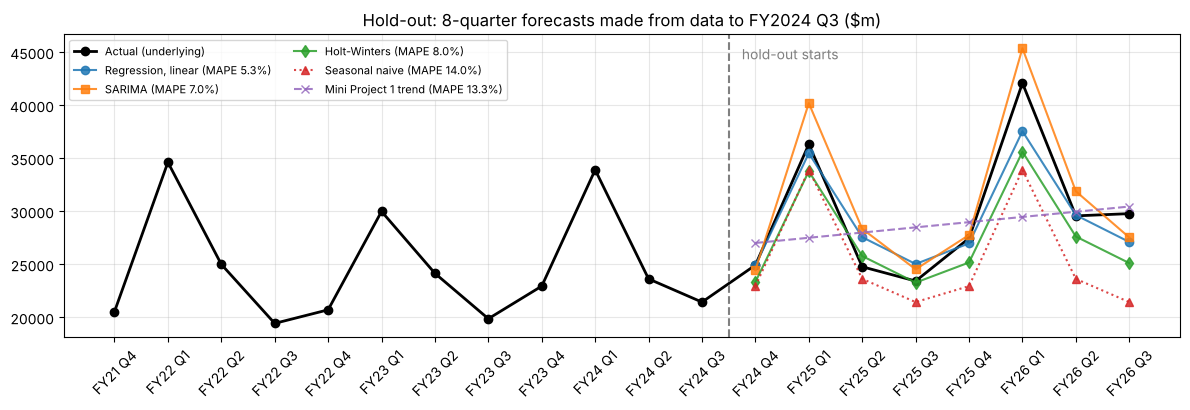

In [10]:
fig, ax = plt.subplots(figsize=(12, 4.2))
idx = np.arange(len(y_all))
ax.plot(idx[-20:], y_all[-20:], "ko-", lw=2, label="Actual (underlying)")
for m, st in [("Regression, linear", "o-"), ("SARIMA", "s-"), ("Holt-Winters", "d-"), ("Seasonal naive", "^:"),
              ("Mini Project 1 trend", "x--")]:
    ax.plot(idx[-H:], ho_fc[m], st, label=f"{m} (MAPE {holdout.loc[m, 'MAPE_%']:.1f}%)", alpha=.85)
ax.axvline(len(y_tr) - .5, c="grey", ls="--"); ax.text(len(y_tr) - .4, ax.get_ylim()[1] * .95, "  hold-out starts", color="grey")
ax.set_xticks(idx[-20:]); ax.set_xticklabels(labels[-20:], rotation=45)
ax.set_title("Hold-out: 8-quarter forecasts made from data to FY2024 Q3 ($m)"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("figures/02_holdout_forecasts.png", dpi=110); plt.show()

## 7. Validation 2: rolling-origin cross-validation (6 origins, 4 quarters ahead)

A single hold-out depends on which period happens to be held out. Rolling-origin CV repeats the exercise from 6
successive starting points: train on all data up to the origin and forecast the next 4 quarters, then move the origin
forward one quarter. That gives 24 forecasts per model, and every model is refitted, with its settings re-chosen, at
each origin.

In [11]:
HCV, N_ORIGINS = 4, 6
origins = range(len(y_all) - HCV - N_ORIGINS + 1, len(y_all) - HCV + 1)
SARIMA_ORDERS.clear()
cv_rows, cv_long = [], []
for o in origins:
    for m in MODELS:
        fc = forecast(m, y_all[:o], q_all[:o], HCV)
        cv_rows.append({"origin": labels[o - 1], "model": m, **metrics(y_all[o:o + HCV], fc)})
        cv_long += [{"origin": labels[o - 1], "model": m, "period": labels[o + k], "horizon": k + 1,
                     "actual": y_all[o + k], "forecast": fc[k]} for k in range(HCV)]
pd.DataFrame(cv_long).to_csv("results/rolling_cv_forecasts.csv", index=False)
cv = score_table(pd.DataFrame(cv_rows))
cv.to_csv("results/rolling_cv_scores.csv")
print("Origins (last training quarter):", [labels[o - 1] for o in origins])
print("SARIMA orders chosen by AIC at each origin:", SARIMA_ORDERS)
cv

Origins (last training quarter): ['FY24 Q2', 'FY24 Q3', 'FY24 Q4', 'FY25 Q1', 'FY25 Q2', 'FY25 Q3']
SARIMA orders chosen by AIC at each origin: [(1, 0, 0, 0, 1, 1), (1, 0, 0, 0, 1, 1), (1, 0, 0, 0, 1, 1), (1, 0, 0, 0, 1, 1), (1, 0, 0, 0, 1, 1), (1, 0, 1, 1, 1, 1)]


,MAE,RMSE,MAPE_%,MAPE_improvement_vs_seasonal_naive_%
model,,,,
SARIMA,"1,652.91","2,023.82",5.74,39.33
"Regression, linear","1,753.47","2,199.32",5.96,37.03
Holt-Winters,"2,602.05","2,976.92",8.41,11.14
Seasonal naive,"2,860.88","3,062.18",9.47,0.00
"Regression, log","3,428.20","4,293.02",11.01,-16.26
MA(4),"4,494.15","6,716.99",13.21,-39.53
Mini Project 1 trend,"4,866.75","6,085.21",15.90,-67.93
Naive,"6,542.25","8,340.11",20.88,-120.54


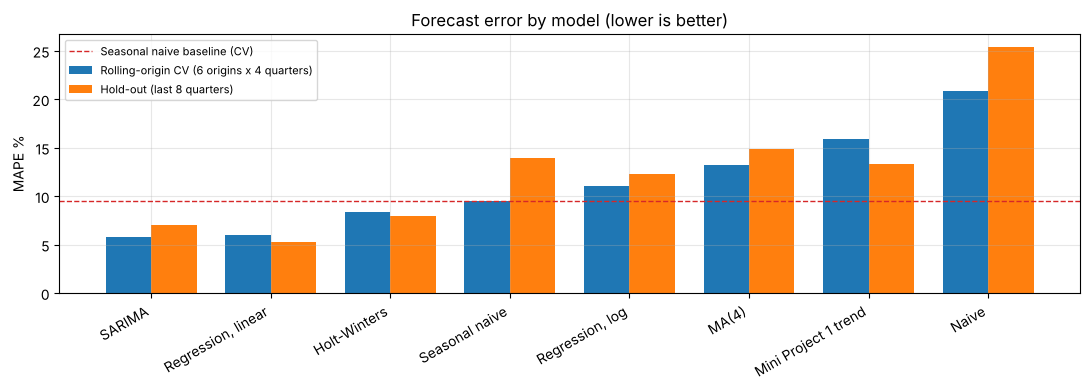

In [12]:
order = cv.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4))
w = .38; x = np.arange(len(order))
ax.bar(x - w / 2, cv["MAPE_%"], w, label="Rolling-origin CV (6 origins x 4 quarters)")
ax.bar(x + w / 2, holdout.loc[order, "MAPE_%"], w, label="Hold-out (last 8 quarters)")
ax.axhline(cv.loc[BASELINE, "MAPE_%"], c="C3", ls="--", lw=1, label="Seasonal naive baseline (CV)")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right"); ax.set_ylabel("MAPE %")
ax.set_title("Forecast error by model (lower is better)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/03_model_comparison_mape.png", dpi=110); plt.show()

## 8. Model selection

**Rule:** choose the model with the lowest **average MAPE across the two validation schemes**. Neither scheme alone
decides, because each rests on a small number of forecasts. The FY2026 Q4 result plays no part in the choice.

In [13]:
combined = pd.DataFrame({"Hold-out MAPE %": holdout["MAPE_%"], "Rolling-CV MAPE %": cv["MAPE_%"]})
combined["Average MAPE %"] = combined.mean(axis=1)
combined["Improvement vs seasonal naive %"] = (1 - combined["Average MAPE %"] / combined.loc[BASELINE, "Average MAPE %"]) * 100
combined = combined.sort_values("Average MAPE %")
combined.to_csv("results/model_selection.csv")
BEST = combined.index[0]
print("Selected model:", BEST)
combined

Selected model: Regression, linear


,Hold-out MAPE %,Rolling-CV MAPE %,Average MAPE %,Improvement vs seasonal naive %
model,,,,
"Regression, linear",5.29,5.96,5.62,51.97
SARIMA,7.00,5.74,6.37,45.60
Holt-Winters,8.00,8.41,8.21,29.91
"Regression, log",12.29,11.01,11.65,0.53
Seasonal naive,13.95,9.47,11.71,0.00
MA(4),14.82,13.21,14.02,-19.70
Mini Project 1 trend,13.29,15.90,14.59,-24.63
Naive,25.42,20.88,23.15,-97.67


**Interpretation**

* Only the models that capture seasonality (linear regression, SARIMA, Holt-Winters) clearly beat seasonal naive.
  On average MAPE, naive, MA(4) and the Mini Project 1 trend line are all worse than simply repeating last year's quarter.
* **Linear regression and SARIMA are close.** SARIMA is slightly better in rolling CV, while the regression is clearly
  better on the 8-quarter hold-out, where longer horizons expose SARIMA's drift. The regression wins on the combined rule.
  It is also the simpler and more explainable of the two.
* The **log** regression does badly. The post-2021 profit jump makes it extrapolate an exponential growth rate that
  did not continue. The additive version is more robust over this period.

## 9. Diagnostics on the selected model (full sample)

In [14]:
d = pd.DataFrame({"NI": y_all, "t": np.arange(len(y_all)), "Q": q_all})
m_best = smf.ols("NI ~ t + C(Q)", data=d).fit()
m_hac = smf.ols("NI ~ t + C(Q)", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
bg_stat, bg_p, _, _ = acorr_breusch_godfrey(m_best, nlags=4)
jb_stat, jb_p, _, _ = jarque_bera(m_best.resid)
bp_stat, bp_p, _, _ = het_breuschpagan(m_best.resid, m_best.model.exog)
print(f"R-squared {m_best.rsquared:.3f}   adj. R-squared {m_best.rsquared_adj:.3f}")
display(pd.DataFrame({"coef": m_best.params, "OLS s.e.": m_best.bse, "Newey-West s.e.": m_hac.bse, "Newey-West p": m_hac.pvalues}))
pd.DataFrame({"statistic": [durbin_watson(m_best.resid), bg_stat, jb_stat, bp_stat], "p_value": [np.nan, bg_p, jb_p, bp_p],
              "tests for": ["autocorrelation (2 = none)", "autocorrelation, 4 lags", "normal residuals", "constant variance"]},
             index=["Durbin-Watson", "Breusch-Godfrey(4)", "Jarque-Bera", "Breusch-Pagan"])

R-squared 0.915   adj. R-squared 0.906


,coef,OLS s.e.,Newey-West s.e.,Newey-West p
Intercept,"16,979.43",998.76,945.31,0.00
C(Q)[T.2],"-9,195.14","1,094.54",877.11,0.00
C(Q)[T.3],"-11,902.18","1,095.91",749.87,0.00
C(Q)[T.4],"-10,508.30","1,121.55",847.44,0.00
t,533.96,31.58,27.89,0.00


,statistic,p_value,tests for
Durbin-Watson,0.82,NaN,autocorrelation (2 = none)
Breusch-Godfrey(4),15.22,0.00,"autocorrelation, 4 lags"
Jarque-Bera,0.15,0.93,normal residuals
Breusch-Pagan,3.69,0.45,constant variance


The trend and all quarter effects remain highly significant with Newey-West (HAC) standard errors, which stay valid
when residuals are autocorrelated. Residuals pass the normality and constant-variance tests, but they are
**autocorrelated**: profit runs above or below trend for several quarters at a time (for example, the post-COVID jump in
FY2021). Point forecasts are still usable, but the prediction intervals should be read as approximate.

## 10. Reality check: FY2026 Q4, forecast before the answer is known

All models are fitted on data up to **FY2026 Q3 (June 2026)**. The forecast is saved first; the actual figure appears
only in the next cell.

In [15]:
f_pt, f_lo, f_hi = reg_forecast("NI ~ t + C(Q)", y_all, q_all, 1)
ytd = df[df.FY == 2026].NI.sum()
frozen = pd.Series({"FY26 Q4 forecast": f_pt[0], "95% PI low": f_lo[0], "95% PI high": f_hi[0],
                    "FY26 Q1-Q3 actual": ytd, "FY26 full-year forecast": ytd + f_pt[0]})
frozen.to_frame("US$ m").to_csv("results/fy26_q4_forecast_frozen.csv")
all_q4 = {m: forecast(m, y_all, q_all, 1)[0] for m in MODELS}
frozen.to_frame("US$ m")

,US$ m
FY26 Q4 forecast,"29,431.23"
95% PI low,"23,804.74"
95% PI high,"35,057.72"
FY26 Q1-Q3 actual,"101,464.00"
FY26 full-year forecast,"130,895.23"


**Actual result.** On 30 Oct 2026 Apple reported FY2026 Q4 (quarter ended 26 Sep 2026) **net income of $30.7bn** and
full-year FY2026 net income of **$132.2bn** (Apple Form 8-K / press release, also reported by MacRumors and iClarified).
Apple gives these to one decimal place in $bn, so the actual is taken as 30,700 ± 50.

In [16]:
ACTUAL_Q4, ACTUAL_FY = 30_700, 132_200
check = pd.DataFrame({"Forecast": [f_pt[0], ytd + f_pt[0]], "Actual (Apple)": [ACTUAL_Q4, ACTUAL_FY]},
                     index=["FY26 Q4", "FY26 full year"])
check["Error"] = check.Forecast - check["Actual (Apple)"]
check["Error %"] = check.Error / check["Actual (Apple)"] * 100
check["Inside 95% PI"] = [bool(f_lo[0] <= ACTUAL_Q4 <= f_hi[0]), "-"]
check.to_csv("results/fy26_q4_vs_actual.csv")
q4_all = pd.DataFrame({"FY26 Q4 forecast": all_q4}).assign(**{"Error %": lambda x: (x["FY26 Q4 forecast"] / ACTUAL_Q4 - 1) * 100})
q4_all.to_csv("results/fy26_q4_all_models.csv")
display(check.round(1))
q4_all.round(1)

,Forecast,Actual (Apple),Error,Error %,Inside 95% PI
FY26 Q4,"29,431.20",30700,"-1,268.80",-4.10,True
FY26 full year,"130,895.20",132200,"-1,304.80",-1.00,-


,FY26 Q4 forecast,Error %
Naive,"29,789.00",-3.00
Seasonal naive,"27,466.00",-10.50
MA(4),"32,232.50",5.00
Mini Project 1 trend,"31,663.80",3.10
"Regression, log","31,220.30",1.70
"Regression, linear","29,431.20",-4.10
Holt-Winters,"32,300.20",5.20
SARIMA,"33,906.60",10.40


**Reading this honestly.** The selected model came within about 4% of the reported quarter and about 1% of the full
year, and the actual figure fell inside its 95% interval. The table above also shows that some other models landed closer
on this single quarter, the Mini Project 1 trend line among them. One quarter is one draw, which is why the model
was chosen on the two validation schemes (8 + 24 forecasts) rather than on this result.

## 11. Forecast for the next 4 quarters (FY2027)

The FY2026 Q4 actual (30,700) is added to the history, and the selected model is refitted to forecast FY2027 Q1–Q4.

In [17]:
y_ext = np.append(y_all, ACTUAL_Q4); q_ext = np.append(q_all, 4)
lab_ext = labels + ["FY26 Q4"]
fut_labels = [f"FY27 Q{k}" for k in range(1, 5)]
p, lo, hi = reg_forecast("NI ~ t + C(Q)", y_ext, q_ext, 4)
fy27 = pd.DataFrame({"forecast": p, "95% PI low": lo, "95% PI high": hi}, index=fut_labels)
fy27.loc["FY27 total"] = [p.sum(), np.nan, np.nan]
fy27["vs same quarter FY26 %"] = list((p / y_ext[-4:] - 1) * 100) + [(p.sum() / ACTUAL_FY - 1) * 100]
fy27.to_csv("results/fy27_forecast.csv")
fy27

,forecast,95% PI low,95% PI high,vs same quarter FY26 %
FY27 Q1,"40,559.99","34,997.02","46,122.96",-3.65
FY27 Q2,"31,898.81","26,335.84","37,461.78",7.85
FY27 Q3,"29,725.72","24,162.75","35,288.69",-0.21
FY27 Q4,"31,768.90","26,205.93","37,331.87",3.48
FY27 total,"133,953.42",NaN,NaN,1.33


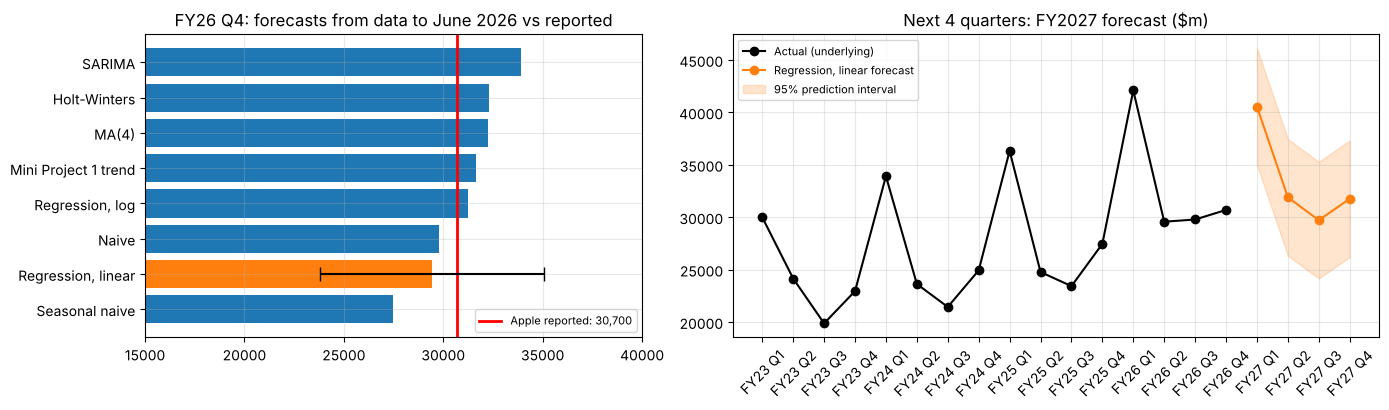

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
q4_sorted = q4_all.sort_values("FY26 Q4 forecast")
ax[0].barh(q4_sorted.index, q4_sorted["FY26 Q4 forecast"], color=["C1" if m == BEST else "C0" for m in q4_sorted.index])
ax[0].axvline(ACTUAL_Q4, c="red", lw=2, label="Apple reported: 30,700")
ax[0].errorbar([f_pt[0]], [list(q4_sorted.index).index(BEST)], xerr=[[f_pt[0] - f_lo[0]], [f_hi[0] - f_pt[0]]], fmt="none", c="k", capsize=5)
ax[0].set_title("FY26 Q4: forecasts from data to June 2026 vs reported"); ax[0].legend(fontsize=8)
ax[0].set_xlim(15000, 40000)
n = len(y_ext); hist = np.arange(n - 16, n); fut = np.arange(n, n + 4)
ax[1].plot(hist, y_ext[-16:], "ko-", label="Actual (underlying)")
ax[1].plot(fut, p, "o-", c="C1", label=f"{BEST} forecast")
ax[1].fill_between(fut, lo, hi, color="C1", alpha=.2, label="95% prediction interval")
ax[1].set_xticks(np.r_[hist, fut]); ax[1].set_xticklabels(lab_ext[-16:] + fut_labels, rotation=45)
ax[1].set_title("Next 4 quarters: FY2027 forecast ($m)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/04_fy26q4_check_and_fy27_forecast.png", dpi=110); plt.show()

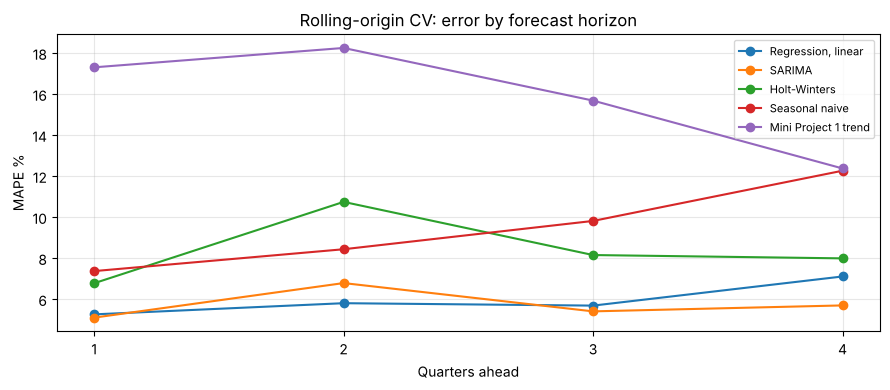

In [19]:
# 5th chart: how error grows with horizon in rolling CV, for the main models
cvl = pd.DataFrame(cv_long); cvl["ape"] = (cvl.forecast - cvl.actual).abs() / cvl.actual * 100
by_h = cvl.pivot_table(index="horizon", columns="model", values="ape", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 4))
for m in ["Regression, linear", "SARIMA", "Holt-Winters", "Seasonal naive", "Mini Project 1 trend"]:
    ax.plot(by_h.index, by_h[m], marker="o", label=m)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Quarters ahead"); ax.set_ylabel("MAPE %")
ax.set_title("Rolling-origin CV: error by forecast horizon"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/05_error_by_horizon.png", dpi=110); plt.show()
by_h.round(1).to_csv("results/rolling_cv_mape_by_horizon.csv")

## 12. Summary of results

In [20]:
b, base = BEST, BASELINE
q4e = check.loc["FY26 Q4", "Error %"]; fye = check.loc["FY26 full year", "Error %"]
summary = f"""
DATA        {len(df)} quarters of Apple net income (FY2016 Q1 - FY2026 Q3), parsed from a messy hand-built Excel file.
            Checks: 0 duplicates, 0 missing quarters, {len(big_moves)} >50% QoQ flags (all seasonal Q1 - false positives),
            10/10 years reconcile. Filing cross-check found 2 offsetting keying errors (FY21 Q1, Q4) the sum check missed.
            FY24 Q4 normalised for a one-off $10.2bn EU tax charge.
MODELS      {len(MODELS)} models: naive, seasonal naive (baseline), MA(4), Mini Project 1 trend, log and linear trend+season
            regression, Holt-Winters, SARIMA (order by AIC on training data only).
VALIDATION  Hold-out (last 8 quarters) + rolling-origin CV (6 origins x 4 quarters = 24 forecasts per model).
SELECTED    {b}: hold-out MAPE {holdout.loc[b,'MAPE_%']:.1f}%, rolling-CV MAPE {cv.loc[b,'MAPE_%']:.1f}%
            vs seasonal naive {holdout.loc[base,'MAPE_%']:.1f}% / {cv.loc[base,'MAPE_%']:.1f}%
            -> {combined.loc[b,'Improvement vs seasonal naive %']:.0f}% lower average MAPE than the seasonal-naive baseline
            -> Mini Project 1 trend line: {holdout.loc['Mini Project 1 trend','MAPE_%']:.1f}% / {cv.loc['Mini Project 1 trend','MAPE_%']:.1f}%
REAL CHECK  FY26 Q4 forecast (data to Jun 2026) {f_pt[0]:,.0f} vs reported {ACTUAL_Q4:,} -> {q4e:+.1f}%, inside 95% PI
            FY26 full year {ytd + f_pt[0]:,.0f} vs reported {ACTUAL_FY:,} -> {fye:+.1f}%
FY2027      Forecast net income {fy27.loc['FY27 total','forecast']:,.0f} ({fy27.loc['FY27 total','vs same quarter FY26 %']:+.1f}% vs FY26)
"""
open("results/summary.txt", "w").write(summary.strip() + "\n")
print(summary)


DATA        43 quarters of Apple net income (FY2016 Q1 - FY2026 Q3), parsed from a messy hand-built Excel file.
            Checks: 0 duplicates, 0 missing quarters, 7 >50% QoQ flags (all seasonal Q1 - false positives),
            10/10 years reconcile. Filing cross-check found 2 offsetting keying errors (FY21 Q1, Q4) the sum check missed.
            FY24 Q4 normalised for a one-off $10.2bn EU tax charge.
MODELS      8 models: naive, seasonal naive (baseline), MA(4), Mini Project 1 trend, log and linear trend+season
            regression, Holt-Winters, SARIMA (order by AIC on training data only).
VALIDATION  Hold-out (last 8 quarters) + rolling-origin CV (6 origins x 4 quarters = 24 forecasts per model).
SELECTED    Regression, linear: hold-out MAPE 5.3%, rolling-CV MAPE 6.0%
            vs seasonal naive 14.0% / 9.5%
            -> 52% lower average MAPE than the seasonal-naive baseline
            -> Mini Project 1 trend line: 13.3% / 15.9%
REAL CHECK  FY26 Q4 forecast (data to J

## 13. Limitations

* With 43 quarters the sample is small, so the validation gives an indication of accuracy, not a guarantee.
* The selected model's residuals are autocorrelated, so its prediction intervals are approximate. Newey-West errors are used for inference.
* A trend model cannot anticipate shocks (demand cycles, tariffs, component costs) or one-off tax items.
* The model forecasts FY2027 Q1 (40.6bn) *below* the record FY2026 Q1 (42.1bn). A linear trend with fixed quarter
  effects does not fully follow the unusually strong FY2026 holiday quarter, so this quarter is the most uncertain.
* The FY2027 forecast extrapolates Apple's own history only. Revenue, margins, guidance or macro variables would be the
  natural next additions.
* The SARIMA order is re-selected at every fit from a small grid, and some fits on ~35 observations did not fully
  converge. This is another reason to prefer the simpler regression.